# Step01: Check and setup Colab environment:

In [2]:
!java -version
!python --version
!nproc
!free -h

[0.017s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.017s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)
Python 3.13.18
2
               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.3Gi       9.0Gi       2.4Mi       2.7Gi        11Gi
Swap:             0B          0B          0B


## Install Hapood

In [3]:
!hadoop version
!hdfs version

/bin/bash: line 1: hadoop: command not found
/bin/bash: line 1: hdfs: command not found


In [4]:
# Download Hadoop 3.5.0
!wget -q https://downloads.apache.org/hadoop/common/hadoop-3.5.0/hadoop-3.5.0.tar.gz

# Extract Hadoop
!tar -xzf hadoop-3.5.0.tar.gz

# Move Hadoop to /usr/local
!mv hadoop-3.5.0 /usr/local/hadoop

# Configure environment variables
import os

os.environ["HADOOP_HOME"] = "/usr/local/hadoop"
os.environ["PATH"] += ":/usr/local/hadoop/bin:/usr/local/hadoop/sbin"
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-21-openjdk-amd64"

# Save environment configuration
!echo 'export HADOOP_HOME=/usr/local/hadoop' >> /etc/profile
!echo 'export JAVA_HOME=/usr/lib/jvm/java-21-openjdk-amd64' >> /etc/profile
!echo 'export PATH=$PATH:$HADOOP_HOME/bin:$HADOOP_HOME/sbin' >> /etc/profile

# Verify installation
!hadoop version
!hdfs version

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Hadoop 3.5.0
Source code repository https://github.com/apache/hadoop.git -r dbcc7cd797100e6b32cd84f85b53a5193a5f9af0
Compiled by cnauroth on 2026-03-24T16:56Z
Compiled on platform linux-x86_64
Compiled with protoc 3.25.5
From source with checksum 64582ed0a62a169c39a19c734a8f33b5
This command was run using /usr/local/hadoop/share/hadoop/common/hadoop-common-3.5.0.jar
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detecte

# Step02: Configure Hadoop for single node HDFS

In [5]:
import os

HADOOP_HOME = "/usr/local/hadoop"
JAVA_HOME = "/usr/lib/jvm/java-21-openjdk-amd64"

os.environ["HADOOP_HOME"] = HADOOP_HOME
os.environ["JAVA_HOME"] = JAVA_HOME
os.environ["PATH"] += ":/usr/local/hadoop/bin:/usr/local/hadoop/sbin"

# Configure Hadoop Java environment
with open(f"{HADOOP_HOME}/etc/hadoop/hadoop-env.sh", "a") as f:
    f.write("\nexport JAVA_HOME=/usr/lib/jvm/java-21-openjdk-amd64\n")

# Configure core-site.xml
core_config = """<?xml version="1.0"?>
<configuration>
    <property>
        <name>fs.defaultFS</name>
        <value>hdfs://localhost:9000</value>
    </property>
</configuration>
"""

with open(f"{HADOOP_HOME}/etc/hadoop/core-site.xml", "w") as f:
    f.write(core_config)

# Configure hdfs-site.xml
hdfs_config = """<?xml version="1.0"?>
<configuration>
    <property>
        <name>dfs.replication</name>
        <value>1</value>
    </property>
    <property>
        <name>dfs.namenode.name.dir</name>
        <value>file:///content/hadoop_data/namenode</value>
    </property>
    <property>
        <name>dfs.datanode.data.dir</name>
        <value>file:///content/hadoop_data/datanode</value>
    </property>
</configuration>
"""

with open(f"{HADOOP_HOME}/etc/hadoop/hdfs-site.xml", "w") as f:
    f.write(hdfs_config)

# Create Hadoop directories
os.makedirs("/content/hadoop_data/namenode", exist_ok=True)
os.makedirs("/content/hadoop_data/datanode", exist_ok=True)

print("Hadoop configuration completed successfully!")

Hadoop configuration completed successfully!


# Step03: Formate the NameNode

In [6]:
!hdfs namenode -format -force

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
2026-11-24 11:04:52,214 INFO namenode.NameNode: STARTUP_MSG: 
/************************************************************
STARTUP_MSG: Starting NameNode
STARTUP_MSG:   host = c9469ec39ec6/172.28.0.12
STARTUP_MSG:   args = [-format, -force]
STARTUP_MSG:   version = 3.5.0
STARTUP_MSG:   classpath = /usr/local/hadoop/etc/hadoop:/usr/local/hadoop/share/hadoop/common/lib/jersey-container-servlet-2.46.jar:/usr/local/hadoop/share/hadoop/common/lib/commons-math3-3.6.1.jar:/usr/local/hadoop/share/hadoop/common/lib/jetty-server-9.4.58.v20250814.jar:/usr/local/hadoop/share/hadoop/common/lib/commons-net-3.9.0.jar:/usr/local/hadoop/share/hadoop/common/lib/nimbus-jose-jwt-10

# Step04: Corrected Hadoop Configuration

In [7]:
import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-21-openjdk-amd64"
os.environ["HADOOP_HOME"] = "/usr/local/hadoop"
os.environ["PATH"] += ":/usr/local/hadoop/bin:/usr/local/hadoop/sbin"

# Start NameNode
!hdfs --daemon start namenode

# Start DataNode
!hdfs --daemon start datanode

# Give services a moment to initialize
import time
time.sleep(5)

print("HDFS services started.")

HDFS services started.


# Step05: Verify HDFS

In [8]:
!jps

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.002s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
1089 NameNode
1234 Jps
1149 DataNode


In [9]:
!hdfs dfsadmin -report

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Configured Capacity: 0 (0 B)
Present Capacity: 0 (0 B)
DFS Remaining: 0 (0 B)
DFS Used: 0 (0 B)
DFS Used%: 0.00%
Replicated Blocks:
	Under replicated blocks: 0
	Blocks with corrupt replicas: 0
	Missing blocks: 0
	Missing blocks (with replication factor 1): 0
	Badly Distributed Blocks: 0
	Low redundancy blocks with highest priority to recover: 0
	Pending deletion blocks: 0
Erasure Coded Block Groups: 
	Low redundancy block groups: 0
	Block groups with corrupt internal blocks: 0
	Missing block groups: 0
	Badly Distributed Blocks: 0
	Low redundancy blocks with highest priority to recover: 0
	Pending deletion blocks: 0

-----------------------------------------------

# Step06: Create Project directories in HDFS

In [10]:
# Create project directories in HDFS
!hdfs dfs -mkdir -p /user/haifaa/nyc_taxi/input
!hdfs dfs -mkdir -p /user/haifaa/nyc_taxi/output

# Verify directories
!hdfs dfs -ls -R /user/haifaa

[0.003s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.003s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
drwxr-xr-x   

# Step07: Upload NYC Taxi dataset

In [11]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train.csv


In [12]:
!ls -lh /content/train.csv

-rw-r--r-- 1 root root 192M Nov 24 11:33 /content/train.csv


In [13]:
!hdfs dfs -put -f /content/train.csv /user/haifaa/nyc_taxi/input/

[0.003s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.003s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


In [14]:
!hdfs dfs -ls /user/haifaa/nyc_taxi/input/

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Found 1 items
-rw-r--r--   1 root supergroup  200589097 2026-11-24 11:33 /user/haifaa/nyc_taxi/input/train.csv


## Inspect dataset

In [15]:
# Display CSV header
!hdfs dfs -cat /user/haifaa/nyc_taxi/input/train.csv | head -1

# Display first 5 records
!hdfs dfs -cat /user/haifaa/nyc_taxi/input/train.csv | head -6

# Count total lines
!hdfs dfs -cat /user/haifaa/nyc_taxi/input/train.csv | wc -l

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
cat: Unable to write to output stream.
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982154846191406,40.767936706542969,-73.964630126953125,40.765602111816406,N,455
id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415344238281,40.738563537597656,-73.999481201171875,40.731151580810547,N,663
id3858529,2,2016-01-19 11:3

# Step08: Create MapReduce Program

# 1St: Number of taxi trips for each pickup hour.

In [16]:
%%writefile /content/TaxiTripsByHour.java

import java.io.IOException;

import org.apache.hadoop.conf.Configuration;
import org.apache.hadoop.fs.Path;
import org.apache.hadoop.io.IntWritable;
import org.apache.hadoop.io.LongWritable;
import org.apache.hadoop.io.Text;
import org.apache.hadoop.mapreduce.Job;
import org.apache.hadoop.mapreduce.Mapper;
import org.apache.hadoop.mapreduce.Reducer;
import org.apache.hadoop.mapreduce.lib.input.FileInputFormat;
import org.apache.hadoop.mapreduce.lib.output.FileOutputFormat;

public class TaxiTripsByHour {

    // Mapper: Extract pickup hour and emit (hour, 1)
    public static class TripMapper
            extends Mapper<LongWritable, Text, Text, LongWritable> {

        private final Text hourKey = new Text();
        private final LongWritable one = new LongWritable(1);

        @Override
        protected void map(
                LongWritable key,
                Text value,
                Context context
        ) throws IOException, InterruptedException {

            String line = value.toString();

            // Skip CSV header
            if (line.startsWith("id,")) {
                return;
            }

            String[] fields = line.split(",", -1);

            // Validate number of columns
            if (fields.length != 11) {
                return;
            }

            String pickupDateTime = fields[2];

            try {
                // Pickup hour is at positions 11 and 12
                if (pickupDateTime.length() >= 13) {
                    String hour = pickupDateTime.substring(11, 13);
                    int hourNumber = Integer.parseInt(hour);

                    if (hourNumber >= 0 && hourNumber <= 23) {
                        hourKey.set(hour);
                        context.write(hourKey, one);
                    }
                }
            } catch (NumberFormatException e) {
                // Ignore invalid timestamps
            }
        }
    }

    // Reducer: Sum all trips for each hour
    public static class TripReducer
            extends Reducer<Text, LongWritable, Text, LongWritable> {

        private final LongWritable result = new LongWritable();

        @Override
        protected void reduce(
                Text key,
                Iterable<LongWritable> values,
                Context context
        ) throws IOException, InterruptedException {

            long totalTrips = 0;

            for (LongWritable value : values) {
                totalTrips += value.get();
            }

            result.set(totalTrips);
            context.write(key, result);
        }
    }

    // Driver: Configure and execute Hadoop job
    public static void main(String[] args) throws Exception {

        if (args.length != 2) {
            System.err.println(
                "Usage: TaxiTripsByHour <input path> <output path>"
            );
            System.exit(2);
        }

        Configuration conf = new Configuration();

        Job job = Job.getInstance(
            conf,
            "NYC Taxi Trips Count By Pickup Hour"
        );

        job.setJarByClass(TaxiTripsByHour.class);

        job.setMapperClass(TripMapper.class);
        job.setCombinerClass(TripReducer.class);
        job.setReducerClass(TripReducer.class);

        job.setOutputKeyClass(Text.class);
        job.setOutputValueClass(LongWritable.class);

        FileInputFormat.addInputPath(job, new Path(args[0]));
        FileOutputFormat.setOutputPath(job, new Path(args[1]));

        System.exit(job.waitForCompletion(true) ? 0 : 1);
    }
}

Writing /content/TaxiTripsByHour.java


## Compile Jave MapReduce

In [17]:
!ls -lh /content/TaxiTripsByHour.java

-rw-r--r-- 1 root root 3.5K Nov 24 11:33 /content/TaxiTripsByHour.java


In [18]:
import os

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-21-openjdk-amd64"
os.environ["HADOOP_HOME"] = "/usr/local/hadoop"
os.environ["PATH"] += ":/usr/local/hadoop/bin"

# Create directory for compiled classes
!mkdir -p /content/taxi_classes

# Compile Java source using Hadoop libraries
!javac -classpath "$(hadoop classpath)" \
-d /content/taxi_classes \
/content/TaxiTripsByHour.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


In [19]:
!jar -cvf /content/taxi-mapreduce.jar -C /content/taxi_classes .

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
added manifest
adding: TaxiTripsByHour$TripMapper.class(in = 2213) (out= 996)(deflated 54%)
adding: TaxiTripsByHour$TripReducer.class(in = 1814) (out= 780)(deflated 57%)
adding: TaxiTripsByHour.class(in = 1718) (out= 952)(deflated 44%)


In [20]:
!ls -lh /content/taxi-mapreduce.jar

-rw-r--r-- 1 root root 3.5K Nov 24 11:33 /content/taxi-mapreduce.jar


In [21]:
# Remove previous output if it exists
!hdfs dfs -rm -r -f /user/haifaa/nyc_taxi/output/trips_by_hour

# Execute Hadoop MapReduce job
!hadoop jar /content/taxi-mapreduce.jar TaxiTripsByHour \
/user/haifaa/nyc_taxi/input/train.csv \
/user/haifaa/nyc_taxi/output/trips_by_hour

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
2026-11-24 11:34:01,590 WARN mapreduce.JobResourceUploader: Hadoop command-line option parsing not performed. Implement the Tool interface and execute your application with ToolRunner to remedy this.
2026-11-24 11:34:01,786 INFO input.FileInputFormat: Total input files to process : 1
2026-11-24 11:34:01,921 INFO mapreduce.JobSubmitter: numb

# Results for trips_by_hours

In [22]:
!hdfs dfs -ls /user/haifaa/nyc_taxi/output/trips_by_hour

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Found 2 items
-rw-r--r--   1 root supergroup          0 2026-11-24 11:34 /user/haifaa/nyc_taxi/output/trips_by_hour/_SUCCESS
-rw-r--r--   1 root supergroup        216 2026-11-24 11:34 /user/haifaa/nyc_taxi/output/trips_by_hour/part-r-00000


In [23]:
!hdfs dfs -cat /user/haifaa/nyc_taxi/output/trips_by_hour/part-r-00000

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.002s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
00	53248
01	38571
02	27972
03	20895
04	15792
05	15002
06	33248
07	55600
08	67053
09	67663
10	65437
11	68476
12	71873
13	71473
14	74292
15	71811
16	64313
17	76483
18	90600
19	90308
20	84072
21	84185
22	80492
23	69785


In [24]:
!hdfs dfs -mkdir -p /user/haifaa/nyc_taxi/results

!hdfs dfs -cp \
/user/haifaa/nyc_taxi/output/trips_by_hour/part-r-00000 \
/user/haifaa/nyc_taxi/results/trips_by_hour.txt

!hdfs dfs -ls /user/haifaa/nyc_taxi/results

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Found 1 items

# 2nd MaprReduce: Average Taxi trip Duration by pickup Hour

In [25]:

%%writefile /content/AverageDurationByHour.java

import java.io.DataInput;
import java.io.DataOutput;
import java.io.IOException;

import org.apache.hadoop.conf.Configuration;
import org.apache.hadoop.fs.Path;
import org.apache.hadoop.io.Writable;
import org.apache.hadoop.io.Text;
import org.apache.hadoop.mapreduce.Job;
import org.apache.hadoop.mapreduce.Mapper;
import org.apache.hadoop.mapreduce.Reducer;
import org.apache.hadoop.mapreduce.lib.input.FileInputFormat;
import org.apache.hadoop.mapreduce.lib.output.FileOutputFormat;

// Stores both sum of durations and count of trips
public class AverageDurationByHour {

    public static class SumCount implements Writable {
        private long sum;
        private long count;

        public SumCount() {
            this.sum = 0;
            this.count = 0;
        }

        public SumCount(long sum, long count) {
            this.sum = sum;
            this.count = count;
        }

        public long getSum() {
            return sum;
        }

        public long getCount() {
            return count;
        }

        @Override
        public void write(DataOutput out) throws IOException {
            out.writeLong(sum);
            out.writeLong(count);
        }

        @Override
        public void readFields(DataInput in) throws IOException {
            sum = in.readLong();
            count = in.readLong();
        }
    }

    // Mapper
    public static class DurationMapper
            extends Mapper<Object, Text, Text, SumCount> {

        private final Text hourKey = new Text();

        @Override
        protected void map(
                Object key,
                Text value,
                Context context
        ) throws IOException, InterruptedException {

            String line = value.toString();

            if (line.startsWith("id,")) {
                return;
            }

            String[] fields = line.split(",", -1);

            if (fields.length != 11) {
                return;
            }

            try {
                String pickupTime = fields[2];
                String hour = pickupTime.substring(11, 13);

                long duration = Long.parseLong(fields[10]);

                int hourNumber = Integer.parseInt(hour);

                if (hourNumber >= 0 && hourNumber <= 23 && duration > 0) {
                    hourKey.set(hour);
                    context.write(hourKey, new SumCount(duration, 1));
                }

            } catch (Exception e) {
                // Ignore invalid records
            }
        }
    }

    // Combiner and Reducer use the same aggregation logic
    public static class SumCountReducer
            extends Reducer<Text, SumCount, Text, SumCount> {

        @Override
        protected void reduce(
                Text key,
                Iterable<SumCount> values,
                Context context
        ) throws IOException, InterruptedException {

            long totalSum = 0;
            long totalCount = 0;

            for (SumCount value : values) {
                totalSum += value.getSum();
                totalCount += value.getCount();
            }

            context.write(key, new SumCount(totalSum, totalCount));
        }
    }

    // Final reducer: calculate average duration
    public static class AverageReducer
            extends Reducer<Text, SumCount, Text, Text> {

        @Override
        protected void reduce(
                Text key,
                Iterable<SumCount> values,
                Context context
        ) throws IOException, InterruptedException {

            long totalSum = 0;
            long totalCount = 0;

            for (SumCount value : values) {
                totalSum += value.getSum();
                totalCount += value.getCount();
            }

            if (totalCount > 0) {
                double average = (double) totalSum / totalCount;

                context.write(
                    key,
                    new Text(String.format("%.2f", average))
                );
            }
        }
    }

    // Driver
    public static void main(String[] args) throws Exception {

        if (args.length != 2) {
            System.err.println(
                "Usage: AverageDurationByHour <input> <output>"
            );
            System.exit(2);
        }

        Configuration conf = new Configuration();

        Job job = Job.getInstance(
            conf,
            "Average Taxi Trip Duration By Pickup Hour"
        );

        job.setJarByClass(AverageDurationByHour.class);

        job.setMapperClass(DurationMapper.class);
        job.setCombinerClass(SumCountReducer.class);
        job.setReducerClass(AverageReducer.class);

        job.setMapOutputKeyClass(Text.class);
        job.setMapOutputValueClass(SumCount.class);

        job.setOutputKeyClass(Text.class);
        job.setOutputValueClass(Text.class);

        FileInputFormat.addInputPath(job, new Path(args[0]));
        FileOutputFormat.setOutputPath(job, new Path(args[1]));

        System.exit(job.waitForCompletion(true) ? 0 : 1);
    }
}


Writing /content/AverageDurationByHour.java


# Complie Java Program

In [26]:
!mkdir -p /content/average_classes

!javac -classpath "$(hadoop classpath)" \
-d /content/average_classes \
/content/AverageDurationByHour.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


## Create JAR file

In [27]:
!jar -cvf /content/average-duration.jar \
-C /content/average_classes .

!ls -lh /content/average-duration.jar

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
added manifest
adding: AverageDurationByHour$AverageReducer.class(in = 2040) (out= 919)(deflated 54%)
adding: AverageDurationByHour$DurationMapper.class(in = 2140) (out= 983)(deflated 54%)
adding: AverageDurationByHour$SumCount.class(in = 972) (out= 558)(deflated 42%)
adding: AverageDurationByHour$SumCountReducer.class(in = 1791) (out= 770)(deflated 57%)
adding: AverageDurationByHour.class(in = 1935) (out= 1030)(deflated 46%)
-rw-r--r-- 1 root root 5.3K Nov 24 11:34 /content/average-duration.jar


## Execute second MapReduce job

In [28]:
!hdfs dfs -rm -r -f /user/haifaa/nyc_taxi/output/average_duration

!hadoop jar /content/average-duration.jar AverageDurationByHour \
/user/haifaa/nyc_taxi/input/train.csv \
/user/haifaa/nyc_taxi/output/average_duration

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
2026-11-24 11:34:53,230 WARN mapreduce.JobResourceUploader: Hadoop command-line option parsing not performed. Implement the Tool interface and execute your application with ToolRunner to remedy this.
2026-11-24 11:34:53,407 INFO input.FileInputFormat: Total input files to process : 1
2026-11-24 11:34:53,518 INFO mapreduce.JobSubmitter: numb

# View Results

In [29]:
!hdfs dfs -cat /user/haifaa/nyc_taxi/output/average_duration/part-r-00000

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
00	936.66
01	903.09
02	890.08
03	890.07
04	921.98
05	822.30
06	797.43
07	831.76
08	924.56
09	933.53
10	933.37
11	966.43
12	993.53
13	1032.25
14	1075.79
15	1118.83
16	1080.15
17	1030.58
18	981.58
19	894.36
20	879.46
21	890.52
22	1023.46
23	925.09


# Third MapReduce job: Trip per taxi vendor

In [30]:

%%writefile /content/TripsByVendor.java

import java.io.IOException;

import org.apache.hadoop.conf.Configuration;
import org.apache.hadoop.fs.Path;
import org.apache.hadoop.io.LongWritable;
import org.apache.hadoop.io.Text;
import org.apache.hadoop.mapreduce.Job;
import org.apache.hadoop.mapreduce.Mapper;
import org.apache.hadoop.mapreduce.Reducer;
import org.apache.hadoop.mapreduce.lib.input.FileInputFormat;
import org.apache.hadoop.mapreduce.lib.output.FileOutputFormat;

public class TripsByVendor {

    // Mapper: Extract vendor ID and emit (vendor, 1)
    public static class VendorMapper
            extends Mapper<LongWritable, Text, Text, LongWritable> {

        private final Text vendorKey = new Text();
        private final LongWritable one = new LongWritable(1);

        @Override
        protected void map(
                LongWritable key,
                Text value,
                Context context
        ) throws IOException, InterruptedException {

            String line = value.toString();

            // Skip CSV header
            if (line.startsWith("id,")) {
                return;
            }

            String[] fields = line.split(",", -1);

            if (fields.length != 11) {
                return;
            }

            String vendor = fields[1];

            if (vendor.equals("1") || vendor.equals("2")) {
                vendorKey.set(vendor);
                context.write(vendorKey, one);
            }
        }
    }

    // Reducer: Calculate total trips per vendor
    public static class VendorReducer
            extends Reducer<Text, LongWritable, Text, LongWritable> {

        private final LongWritable result = new LongWritable();

        @Override
        protected void reduce(
                Text key,
                Iterable<LongWritable> values,
                Context context
        ) throws IOException, InterruptedException {

            long totalTrips = 0;

            for (LongWritable value : values) {
                totalTrips += value.get();
            }

            result.set(totalTrips);
            context.write(key, result);
        }
    }

    // Driver
    public static void main(String[] args) throws Exception {

        if (args.length != 2) {
            System.err.println(
                "Usage: TripsByVendor <input> <output>"
            );
            System.exit(2);
        }

        Configuration conf = new Configuration();

        Job job = Job.getInstance(
            conf,
            "NYC Taxi Trips By Vendor"
        );

        job.setJarByClass(TripsByVendor.class);

        job.setMapperClass(VendorMapper.class);
        job.setCombinerClass(VendorReducer.class);
        job.setReducerClass(VendorReducer.class);

        job.setOutputKeyClass(Text.class);
        job.setOutputValueClass(LongWritable.class);

        FileInputFormat.addInputPath(job, new Path(args[0]));
        FileOutputFormat.setOutputPath(job, new Path(args[1]));

        System.exit(job.waitForCompletion(true) ? 0 : 1);
    }
}


Writing /content/TripsByVendor.java


## Compile Java programe

In [31]:
!mkdir -p /content/vendor_classes

!javac -classpath "$(hadoop classpath)" \
-d /content/vendor_classes \
/content/TripsByVendor.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


## Create Jar file

In [32]:
!jar -cvf /content/vendor-analysis.jar \
-C /content/vendor_classes .

!ls -lh /content/vendor-analysis.jar

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
added manifest
adding: TripsByVendor$VendorMapper.class(in = 2036) (out= 889)(deflated 56%)
adding: TripsByVendor$VendorReducer.class(in = 1812) (out= 782)(deflated 56%)
adding: TripsByVendor.class(in = 1695) (out= 936)(deflated 44%)
-rw-r--r-- 1 root root 3.3K Nov 24 11:35 /content/vendor-analysis.jar


# Execute third Mapreduce

In [33]:
!hdfs dfs -rm -r -f /user/haifaa/nyc_taxi/output/vendor_analysis

!hadoop jar /content/vendor-analysis.jar TripsByVendor \
/user/haifaa/nyc_taxi/input/train.csv \
/user/haifaa/nyc_taxi/output/vendor_analysis

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
2026-11-24 11:35:20,184 WARN mapreduce.JobResourceUploader: Hadoop command-line option parsing not performed. Implement the Tool interface and execute your application with ToolRunner to remedy this.
2026-11-24 11:35:20,334 INFO input.FileInputFormat: Total input files to process : 1
2026-11-24 11:35:20,446 INFO mapreduce.JobSubmitter: numb

# View results

In [34]:
!hdfs dfs -cat /user/haifaa/nyc_taxi/output/vendor_analysis/part-r-00000

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
1	678342
2	780302


# Fourt Mapreduce job: Passenger Distribution

In [35]:

%%writefile /content/PassengerDistribution.java

import java.io.IOException;

import org.apache.hadoop.conf.Configuration;
import org.apache.hadoop.fs.Path;
import org.apache.hadoop.io.LongWritable;
import org.apache.hadoop.io.Text;
import org.apache.hadoop.mapreduce.Job;
import org.apache.hadoop.mapreduce.Mapper;
import org.apache.hadoop.mapreduce.Reducer;
import org.apache.hadoop.mapreduce.lib.input.FileInputFormat;
import org.apache.hadoop.mapreduce.lib.output.FileOutputFormat;

public class PassengerDistribution {

    // Mapper: Extract passenger count and emit (count, 1)
    public static class PassengerMapper
            extends Mapper<LongWritable, Text, Text, LongWritable> {

        private final Text passengerKey = new Text();
        private final LongWritable one = new LongWritable(1);

        @Override
        protected void map(
                LongWritable key,
                Text value,
                Context context
        ) throws IOException, InterruptedException {

            String line = value.toString();

            // Skip CSV header
            if (line.startsWith("id,")) {
                return;
            }

            String[] fields = line.split(",", -1);

            if (fields.length != 11) {
                return;
            }

            try {
                int passengers = Integer.parseInt(fields[4]);

                if (passengers >= 0) {
                    passengerKey.set(String.valueOf(passengers));
                    context.write(passengerKey, one);
                }

            } catch (NumberFormatException e) {
                // Ignore invalid records
            }
        }
    }

    // Reducer: Sum trips for each passenger count
    public static class PassengerReducer
            extends Reducer<Text, LongWritable, Text, LongWritable> {

        private final LongWritable result = new LongWritable();

        @Override
        protected void reduce(
                Text key,
                Iterable<LongWritable> values,
                Context context
        ) throws IOException, InterruptedException {

            long totalTrips = 0;

            for (LongWritable value : values) {
                totalTrips += value.get();
            }

            result.set(totalTrips);
            context.write(key, result);
        }
    }

    // Driver
    public static void main(String[] args) throws Exception {

        if (args.length != 2) {
            System.err.println(
                "Usage: PassengerDistribution <input> <output>"
            );
            System.exit(2);
        }

        Configuration conf = new Configuration();

        Job job = Job.getInstance(
                conf,
                "NYC Taxi Passenger Distribution"
        );

        job.setJarByClass(PassengerDistribution.class);

        job.setMapperClass(PassengerMapper.class);
        job.setCombinerClass(PassengerReducer.class);
        job.setReducerClass(PassengerReducer.class);

        job.setOutputKeyClass(Text.class);
        job.setOutputValueClass(LongWritable.class);

        FileInputFormat.addInputPath(job, new Path(args[0]));
        FileOutputFormat.setOutputPath(job, new Path(args[1]));

        System.exit(job.waitForCompletion(true) ? 0 : 1);
    }
}


Writing /content/PassengerDistribution.java


## Compile Java programe

In [36]:
!mkdir -p /content/passenger_classes

!javac -classpath "$(hadoop classpath)" \
-d /content/passenger_classes \
/content/PassengerDistribution.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


## Create Jar file

In [37]:
!jar -cvf /content/passenger-analysis.jar \
-C /content/passenger_classes .

!ls -lh /content/passenger-analysis.jar

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
added manifest
adding: PassengerDistribution$PassengerMapper.class(in = 2172) (out= 941)(deflated 56%)
adding: PassengerDistribution$PassengerReducer.class(in = 1842) (out= 787)(deflated 57%)
adding: PassengerDistribution.class(in = 1754) (out= 941)(deflated 46%)
-rw-r--r-- 1 root root 3.5K Nov 24 11:35 /content/passenger-analysis.jar


## Execute Hadoop job

In [38]:
!hdfs dfs -rm -r -f /user/haifaa/nyc_taxi/output/passenger_distribution

!hadoop jar /content/passenger-analysis.jar PassengerDistribution \
/user/haifaa/nyc_taxi/input/train.csv \
/user/haifaa/nyc_taxi/output/passenger_distribution

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
2026-11-24 11:35:45,644 WARN mapreduce.JobResourceUploader: Hadoop command-line option parsing not performed. Implement the Tool interface and execute your application with ToolRunner to remedy this.
2026-11-24 11:35:45,786 INFO input.FileInputFormat: Total input files to process : 1
2026-11-24 11:35:45,898 INFO mapreduce.JobSubmitter: numb

## Show Results

In [39]:
!hdfs dfs -cat /user/haifaa/nyc_taxi/output/passenger_distribution/part-r-00000

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
0	60
1	1033540
2	210318
3	59896
4	28404
5	78088
6	48333
7	3
8	1
9	1


# Fifth MapReduce Job: Daily Taxi Trip Count

In [40]:

%%writefile /content/DailyTrips.java

import java.io.IOException;

import org.apache.hadoop.conf.Configuration;
import org.apache.hadoop.fs.Path;
import org.apache.hadoop.io.LongWritable;
import org.apache.hadoop.io.Text;
import org.apache.hadoop.mapreduce.Job;
import org.apache.hadoop.mapreduce.Mapper;
import org.apache.hadoop.mapreduce.Reducer;
import org.apache.hadoop.mapreduce.lib.input.FileInputFormat;
import org.apache.hadoop.mapreduce.lib.output.FileOutputFormat;

public class DailyTrips {

    // Mapper: Extract pickup date and emit (date, 1)
    public static class DailyMapper
            extends Mapper<LongWritable, Text, Text, LongWritable> {

        private final Text dateKey = new Text();
        private final LongWritable one = new LongWritable(1);

        @Override
        protected void map(
                LongWritable key,
                Text value,
                Context context
        ) throws IOException, InterruptedException {

            String line = value.toString();

            // Skip CSV header
            if (line.startsWith("id,")) {
                return;
            }

            String[] fields = line.split(",", -1);

            if (fields.length != 11) {
                return;
            }

            String pickupDateTime = fields[2];

            if (pickupDateTime.length() >= 10) {
                String pickupDate = pickupDateTime.substring(0, 10);

                dateKey.set(pickupDate);
                context.write(dateKey, one);
            }
        }
    }

    // Reducer: Calculate daily trip totals
    public static class DailyReducer
            extends Reducer<Text, LongWritable, Text, LongWritable> {

        private final LongWritable result = new LongWritable();

        @Override
        protected void reduce(
                Text key,
                Iterable<LongWritable> values,
                Context context
        ) throws IOException, InterruptedException {

            long totalTrips = 0;

            for (LongWritable value : values) {
                totalTrips += value.get();
            }

            result.set(totalTrips);
            context.write(key, result);
        }
    }

    // Driver
    public static void main(String[] args) throws Exception {

        if (args.length != 2) {
            System.err.println("Usage: DailyTrips <input> <output>");
            System.exit(2);
        }

        Configuration conf = new Configuration();

        Job job = Job.getInstance(
                conf,
                "NYC Taxi Daily Trip Count"
        );

        job.setJarByClass(DailyTrips.class);

        job.setMapperClass(DailyMapper.class);
        job.setCombinerClass(DailyReducer.class);
        job.setReducerClass(DailyReducer.class);

        job.setOutputKeyClass(Text.class);
        job.setOutputValueClass(LongWritable.class);

        FileInputFormat.addInputPath(job, new Path(args[0]));
        FileOutputFormat.setOutputPath(job, new Path(args[1]));

        System.exit(job.waitForCompletion(true) ? 0 : 1);
    }
}


Writing /content/DailyTrips.java


## Compile Programe

In [41]:
!mkdir -p /content/daily_classes

!javac -classpath "$(hadoop classpath)" \
-d /content/daily_classes \
/content/DailyTrips.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


## Create JAR

In [42]:
!jar -cvf /content/daily-trips.jar \
-C /content/daily_classes .

!ls -lh /content/daily-trips.jar

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
added manifest
adding: DailyTrips$DailyMapper.class(in = 2041) (out= 898)(deflated 56%)
adding: DailyTrips$DailyReducer.class(in = 1801) (out= 779)(deflated 56%)
adding: DailyTrips.class(in = 1677) (out= 937)(deflated 44%)
-rw-r--r-- 1 root root 3.3K Nov 24 11:36 /content/daily-trips.jar


Excute fifth MapReduce

In [43]:
!hdfs dfs -rm -r -f /user/haifaa/nyc_taxi/output/daily_trips

!hadoop jar /content/daily-trips.jar DailyTrips \
/user/haifaa/nyc_taxi/input/train.csv \
/user/haifaa/nyc_taxi/output/daily_trips

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
2026-11-24 11:36:10,943 WARN mapreduce.JobResourceUploader: Hadoop command-line option parsing not performed. Implement the Tool interface and execute your application with ToolRunner to remedy this.
2026-11-24 11:36:11,115 INFO input.FileInputFormat: Total input files to process : 1
2026-11-24 11:36:11,223 INFO mapreduce.JobSubmitter: numb

## Display Results

In [44]:
!hdfs dfs -cat /user/haifaa/nyc_taxi/output/daily_trips/part-r-00000 | head -20

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
2016-01-01	7162
2016-01-02	6512
2016-01-03	6353
2016-01-04	6725
2016-01-05	7204
2016-01-06	7365
2016-01-07	7649
2016-01-08	8229
2016-01-09	8578
2016-01-10	7454
2016-01-11	7276
2016-01-12	7794
2016-01-13	8360
2016-01-14	8277
2016-01-15	8539
2016-01-16	8797
2016-01-17	7891
2016-01-18	7146


# Validate Results

In [45]:
import os
import pandas as pd

output_dir = "/content/nyc_taxi_results"
os.makedirs(output_dir, exist_ok=True)

base = "/user/haifaa/nyc_taxi/output"

# Download Hadoop results from HDFS
files = {
    "hourly_trips": f"{base}/trips_by_hour/part-r-00000",
    "average_duration": f"{base}/average_duration/part-r-00000",
    "vendor_analysis": f"{base}/vendor_analysis/part-r-00000",
    "passenger_distribution": f"{base}/passenger_distribution/part-r-00000",
    "daily_trips": f"{base}/daily_trips/part-r-00000"
}

for name, hdfs_path in files.items():
    local_path = f"{output_dir}/{name}.txt"
    !hdfs dfs -get -f {hdfs_path} {local_path}
    print(f"Downloaded: {name}")

print("\nAll five result files downloaded.")

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Downloaded: hourly_trips
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Downloaded: average_duration
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-chil

In [46]:
# Load all Hadoop output files
hourly = pd.read_csv(
    f"{output_dir}/hourly_trips.txt",
    sep="\t", header=None,
    names=["hour", "trips"]
)

average = pd.read_csv(
    f"{output_dir}/average_duration.txt",
    sep="\t", header=None,
    names=["hour", "average_seconds"]
)

vendor = pd.read_csv(
    f"{output_dir}/vendor_analysis.txt",
    sep="\t", header=None,
    names=["vendor", "trips"]
)

passengers = pd.read_csv(
    f"{output_dir}/passenger_distribution.txt",
    sep="\t", header=None,
    names=["passengers", "trips"]
)

daily = pd.read_csv(
    f"{output_dir}/daily_trips.txt",
    sep="\t", header=None,
    names=["date", "trips"]
)

# Display validation summary
print("========== VALIDATION SUMMARY ==========")

print("Hourly total:", hourly["trips"].sum())
print("Vendor total:", vendor["trips"].sum())
print("Passenger total:", passengers["trips"].sum())
print("Daily total:", daily["trips"].sum())

print("\nNumber of pickup hours:", len(hourly))
print("Number of vendors:", len(vendor))
print("Passenger categories:", len(passengers))
print("Number of dates:", len(daily))

print("\nDaily date range:")
print(daily["date"].min(), "to", daily["date"].max())

print("\nDaily records:")
print(daily.head())

========== VALIDATION SUMMARY ==========
Hourly total: 1458644
Vendor total: 1458644
Passenger total: 1458644
Daily total: 1458644

Number of pickup hours: 24
Number of vendors: 2
Passenger categories: 10
Number of dates: 182

Daily date range:
2016-01-01 to 2016-06-30

Daily records:
         date  trips
0  2016-01-01   7162
1  2016-01-02   6512
2  2016-01-03   6353
3  2016-01-04   6725
4  2016-01-05   7204


In [47]:
print("Hourly:", hourly.columns.tolist())
print("Average:", average.columns.tolist())
print("Vendor:", vendor.columns.tolist())
print("Passengers:", passengers.columns.tolist())
print("Daily:", daily.columns.tolist())

Hourly: ['hour', 'trips']
Average: ['hour', 'average_seconds']
Vendor: ['vendor', 'trips']
Passengers: ['passengers', 'trips']
Daily: ['date', 'trips']


# Create all results Charts

In [48]:
passengers = pd.read_csv(
    "/content/nyc_taxi_results/passenger_distribution.txt",
    sep="\t",
    header=None,
    names=["passenger_count", "trips"]
)

print(passengers.head())

   passenger_count    trips
0                0       60
1                1  1033540
2                2   210318
3                3    59896
4                4    28404


In [49]:
import os
import matplotlib.pyplot as plt

output_dir = "/content/nyc_taxi_results"
os.makedirs(output_dir, exist_ok=True)

print("Output folder ready:", output_dir)

Output folder ready: /content/nyc_taxi_results


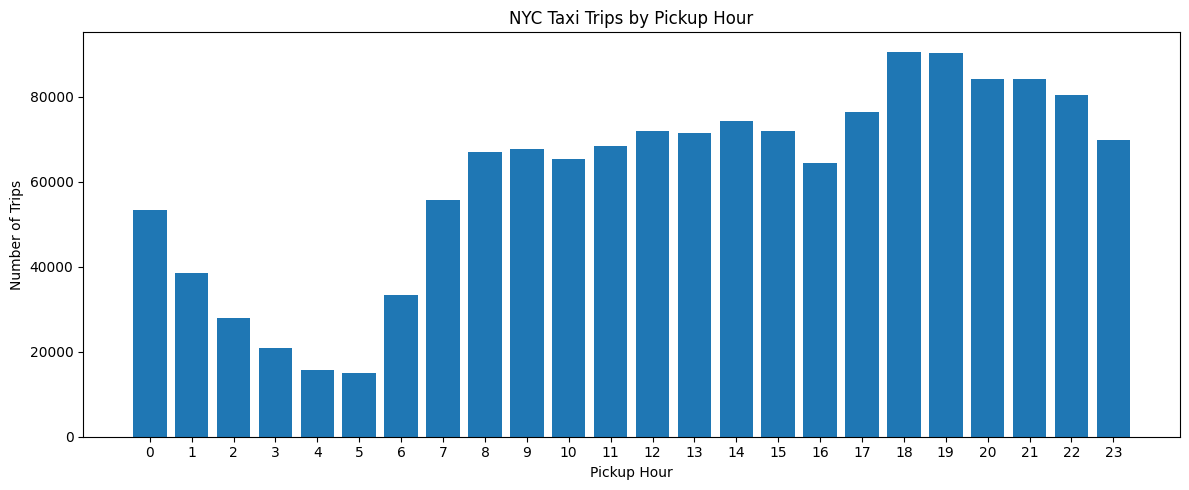

In [50]:
plt.figure(figsize=(12, 5))
plt.bar(hourly["hour"].astype(str), hourly["trips"])

plt.title("NYC Taxi Trips by Pickup Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Number of Trips")

plt.tight_layout()
plt.savefig(f"{output_dir}/1_trips_by_hour.png", dpi=300)
plt.show()

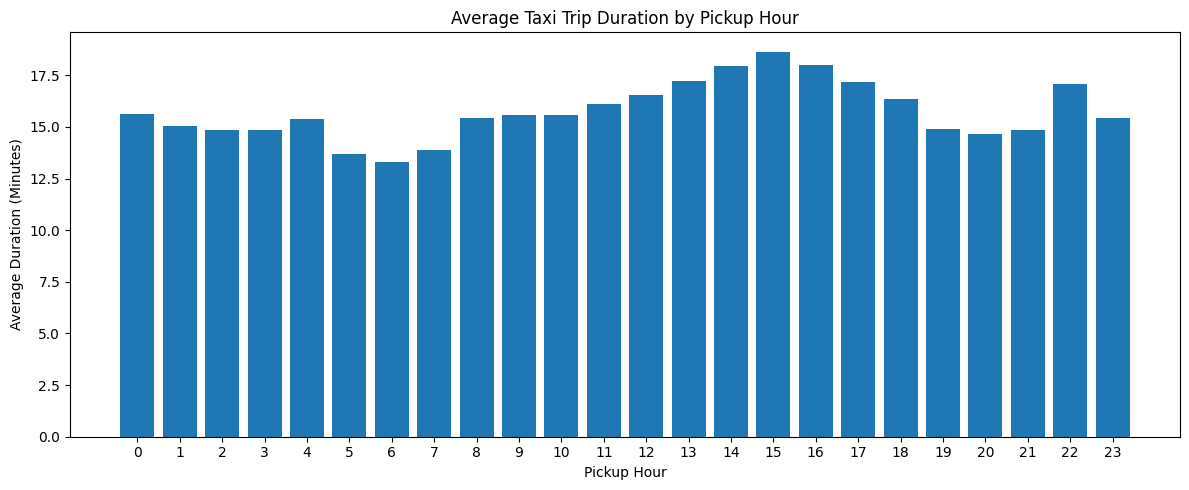

In [51]:
plt.figure(figsize=(12, 5))
plt.bar(average["hour"].astype(str), average["average_seconds"] / 60)

plt.title("Average Taxi Trip Duration by Pickup Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Average Duration (Minutes)")

plt.tight_layout()
plt.savefig(f"{output_dir}/2_average_duration.png", dpi=300)
plt.show()

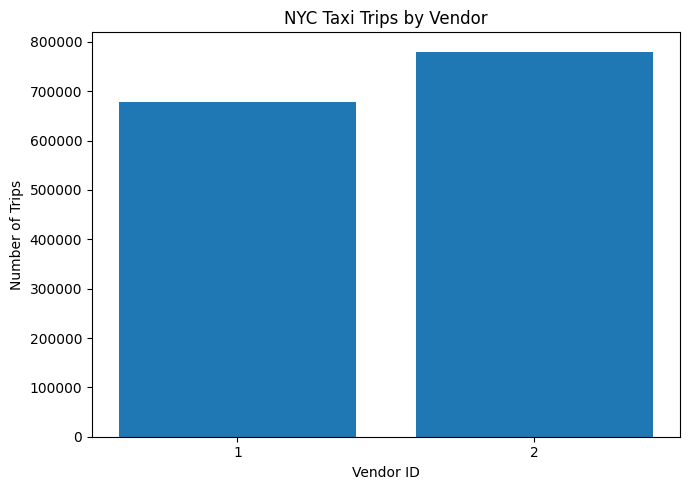

In [52]:
plt.figure(figsize=(7, 5))
plt.bar(vendor["vendor"].astype(str), vendor["trips"])

plt.title("NYC Taxi Trips by Vendor")
plt.xlabel("Vendor ID")
plt.ylabel("Number of Trips")

plt.tight_layout()
plt.savefig(f"{output_dir}/3_vendor_analysis.png", dpi=300)
plt.show()

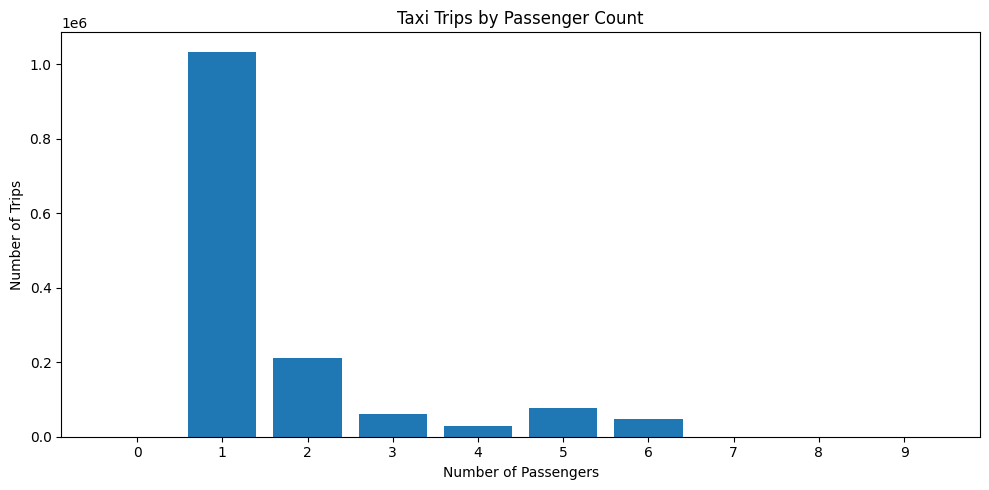

In [53]:
plt.figure(figsize=(10, 5))
plt.bar(passengers["passenger_count"].astype(str), passengers["trips"])

plt.title("Taxi Trips by Passenger Count")
plt.xlabel("Number of Passengers")
plt.ylabel("Number of Trips")

plt.tight_layout()
plt.savefig(f"{output_dir}/4_passenger_distribution.png", dpi=300)
plt.show()

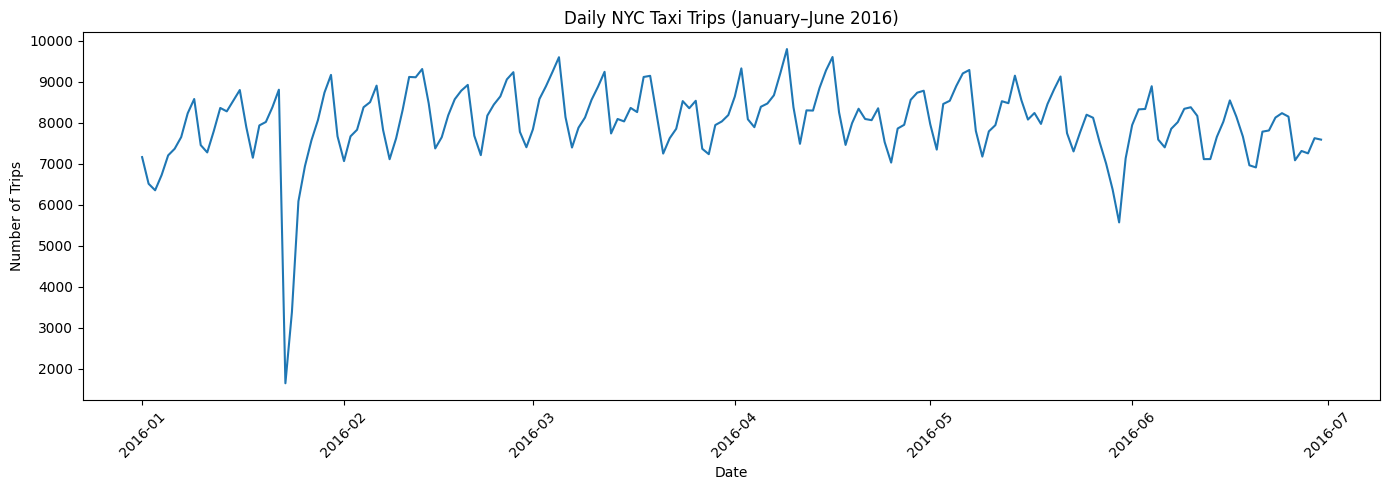

In [54]:
daily["date"] = pd.to_datetime(daily["date"])

plt.figure(figsize=(14, 5))
plt.plot(daily["date"], daily["trips"])

plt.title("Daily NYC Taxi Trips (January–June 2016)")
plt.xlabel("Date")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(f"{output_dir}/5_daily_trips.png", dpi=300)
plt.show()

In [55]:
print("Generated chart files:")

for filename in sorted(os.listdir(output_dir)):
    if filename.endswith(".png"):
        print(filename)

Generated chart files:
1_trips_by_hour.png
2_average_duration.png
3_vendor_analysis.png
4_passenger_distribution.png
5_daily_trips.png


#  Save Charts and code files

In [56]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/nyc_taxi_charts",
    "zip",
    output_dir
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [57]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [58]:
import os

project_dir = "/content/drive/MyDrive/NYC_Taxi_MapReduce"

os.makedirs(project_dir, exist_ok=True)

print("Project folder created successfully!")

Project folder created successfully!


In [59]:
folders = [
    "Charts",
    "Results",
    "Java_Source_Code",
    "JAR_Files",
    "Screenshots"
]

for folder in folders:
    os.makedirs(os.path.join(project_dir, folder), exist_ok=True)

print("All project folders created!")

All project folders created!


In [60]:
import shutil

for filename in os.listdir("/content/nyc_taxi_results"):
    if filename.endswith(".png"):
        shutil.copy2(
            os.path.join("/content/nyc_taxi_results", filename),
            os.path.join(project_dir, "Charts", filename)
        )

print("All five charts saved to Google Drive!")

All five charts saved to Google Drive!


In [61]:
print(os.listdir(os.path.join(project_dir, "Charts")))

['1_trips_by_hour.png', '3_vendor_analysis.png', '2_average_duration.png', '4_passenger_distribution.png', '5_daily_trips.png']


In [62]:
import os
import subprocess
import shutil

results_dir = os.path.join(project_dir, "Results")
os.makedirs(results_dir, exist_ok=True)

hdfs_files = {
    "hourly_trips.txt": "/user/haifaa/nyc_taxi/output/trips_by_hour/part-r-00000",
    "average_duration.txt": "/user/haifaa/nyc_taxi/output/average_duration/part-r-00000",
    "vendor_analysis.txt": "/user/haifaa/nyc_taxi/output/vendor_analysis/part-r-00000",
    "passenger_distribution.txt": "/user/haifaa/nyc_taxi/output/passenger_distribution/part-r-00000",
    "daily_trips.txt": "/user/haifaa/nyc_taxi/output/daily_trips/part-r-00000"
}

for filename, hdfs_path in hdfs_files.items():
    local_path = f"/content/{filename}"

    subprocess.run(
        ["hdfs", "dfs", "-get", "-f", hdfs_path, local_path],
        check=True
    )

    shutil.copy2(
        local_path,
        os.path.join(results_dir, filename)
    )

    print("Saved:", filename)

print("\nAll five Hadoop result files saved successfully!")

Saved: hourly_trips.txt
Saved: average_duration.txt
Saved: vendor_analysis.txt
Saved: passenger_distribution.txt
Saved: daily_trips.txt

All five Hadoop result files saved successfully!


In [63]:
print("Saved result files:")

for filename in sorted(os.listdir(results_dir)):
    print(filename)

Saved result files:
average_duration.txt
daily_trips.txt
evidence_hourly.txt
hourly_trips.txt
passenger_distribution.txt
vendor_analysis.txt


In [64]:
import os

for root, dirs, files_list in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in ["drive", ".cache"]]

    for filename in files_list:
        if filename.endswith(".java"):
            print(os.path.join(root, filename))


/content/DailyTrips.java
/content/TaxiTripsByHour.java
/content/TripsByVendor.java
/content/AverageDurationByHour.java
/content/PassengerDistribution.java


In [65]:
import os
import shutil

source_dir = "/content"
java_dir = os.path.join(project_dir, "Java_Source_Code")

java_files = [
    "PassengerDistribution.java",
    "TripsByVendor.java",
    "DailyTrips.java",
    "TaxiTripsByHour.java",
    "AverageDurationByHour.java"
]

for filename in java_files:
    source = os.path.join(source_dir, filename)
    destination = os.path.join(java_dir, filename)

    shutil.copy2(source, destination)
    print("Saved:", filename)

print("\nAll Java source files saved successfully!")

Saved: PassengerDistribution.java
Saved: TripsByVendor.java
Saved: DailyTrips.java
Saved: TaxiTripsByHour.java
Saved: AverageDurationByHour.java

All Java source files saved successfully!


In [66]:
print(os.listdir(java_dir))

['TaxiTripsByHour.java', 'AverageDurationByHour.java', 'TripsByVendor.java', 'PassengerDistribution.java', 'DailyTrips.java']


In [67]:
import glob

jar_files = glob.glob("/content/*.jar")

print("Found JAR files:")
for jar in jar_files:
    print(jar)

Found JAR files:
/content/taxi-mapreduce.jar
/content/passenger-analysis.jar
/content/daily-trips.jar
/content/average-duration.jar
/content/vendor-analysis.jar


In [68]:
import os
import shutil
import glob

jar_dir = os.path.join(project_dir, "JAR_Files")
os.makedirs(jar_dir, exist_ok=True)

jar_files = glob.glob("/content/*.jar")

for jar_path in jar_files:
    shutil.copy2(
        jar_path,
        os.path.join(jar_dir, os.path.basename(jar_path))
    )
    print("Saved:", os.path.basename(jar_path))

print("\nAll JAR files saved successfully!")

Saved: taxi-mapreduce.jar
Saved: passenger-analysis.jar
Saved: daily-trips.jar
Saved: average-duration.jar
Saved: vendor-analysis.jar

All JAR files saved successfully!


In [69]:
print("Saved JAR files:")

for filename in sorted(os.listdir(jar_dir)):
    print(filename)

Saved JAR files:
average-duration.jar
daily-trips.jar
passenger-analysis.jar
taxi-mapreduce.jar
vendor-analysis.jar


In [70]:
for root, dirs, files_list in os.walk(project_dir):
    level = root.replace(project_dir, "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")

    for filename in sorted(files_list):
        print(f"{indent}    {filename}")

NYC_Taxi_MapReduce/
    Charts/
        1_trips_by_hour.png
        2_average_duration.png
        3_vendor_analysis.png
        4_passenger_distribution.png
        5_daily_trips.png
    Results/
        average_duration.txt
        daily_trips.txt
        evidence_hourly.txt
        hourly_trips.txt
        passenger_distribution.txt
        vendor_analysis.txt
    Java_Source_Code/
        AverageDurationByHour.java
        DailyTrips.java
        PassengerDistribution.java
        TaxiTripsByHour.java
        TripsByVendor.java
    JAR_Files/
        average-duration.jar
        daily-trips.jar
        passenger-analysis.jar
        taxi-mapreduce.jar
        vendor-analysis.jar
    Screenshots/


In [71]:
!jps

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
1089 NameNode
11971 Jps
1149 DataNode


In [72]:
!hdfs dfs -ls /user/haifaa/nyc_taxi/input

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Found 1 items
-rw-r--r--   1 root supergroup  200589097 2026-11-24 11:33 /user/haifaa/nyc_taxi/input/train.csv


In [73]:
!hdfs dfs -ls /user/haifaa/nyc_taxi/output

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Found 5 items
drwxr-xr-x   - root supergroup          0 2026-11-24 11:35 /user/haifaa/nyc_taxi/output/average_duration
drwxr-xr-x   - root supergroup          0 2026-11-24 11:36 /user/haifaa/nyc_taxi/output/daily_trips
drwxr-xr-x   - root supergroup          0 2026-11-24 11:35 /user/haifaa/nyc_taxi/output/passenger_distribution
drwxr-xr-x   - root supergroup          0 2026-11-24 11:34 /user/haifaa/nyc_taxi/output/trips_by_hour
drwxr-xr-x   - root supergroup          0 2026-11-24 11:35 /user/haifaa/nyc_taxi/output/vendor_analysis


In [74]:
!hadoop jar /content/taxi-mapreduce.jar TaxiTripsByHour \
/user/haifaa/nyc_taxi/input/train.csv \
/user/haifaa/nyc_taxi/output/evidence_hourly

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
2026-11-24 11:39:18,656 WARN mapreduce.JobResourceUploader: Hadoop command-line option parsing not performed. Implement the Tool interface and execute your application with ToolRunner to remedy this.
2026-11-24 11:39:18,800 INFO input.FileInputFormat: Total input files to process : 1
2026-11-24 11:39:18,920 INFO mapreduce.JobSubmitter: number of splits:2
2026-11-24 11:39:19,271 INFO mapreduce.JobSubmitter: Submitting tokens for job: job_local222903087_0001
2026-11-24 11:39:19,276 INFO mapreduce.JobSubmitter: Executing with tokens: []
2026-11-24 11:39:19,601 INFO mapred.LocalJobRunner: OutputCommitter set in config null
2026-11-24 11:39:19,602 INFO mapreduce.Job: 

In [75]:
!hdfs dfs -cat /user/haifaa/nyc_taxi/output/evidence_hourly/part-r-00000

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
00	53248
01	38571
02	27972
03	20895
04	15792
05	15002
06	33248
07	55600
08	67053
09	67663
10	65437
11	68476
12	71873
13	71473
14	74292
15	71811
16	64313
17	76483
18	90600
19	90308
20	84072
21	84185
22	80492
23	69785


In [76]:
import os
import subprocess
import shutil

screenshot_evidence_dir = os.path.join(project_dir, "Screenshots")
os.makedirs(screenshot_evidence_dir, exist_ok=True)

local_file = "/content/evidence_hourly.txt"

subprocess.run([
    "hdfs", "dfs", "-get", "-f",
    "/user/haifaa/nyc_taxi/output/evidence_hourly/part-r-00000",
    local_file
], check=True)

shutil.copy2(
    local_file,
    os.path.join(results_dir, "evidence_hourly.txt")
)

print("Hourly execution output saved!")

Hourly execution output saved!


In [77]:
from IPython.display import display, Markdown

log_path = os.path.join(
    project_dir,
    "Screenshots",
    "hourly_mapreduce_execution_log.txt"
)

with open(log_path, "r") as f:
    log = f.read()

# Display only the important execution evidence
keywords = [
    "number of splits",
    "map 100% reduce 100%",
    "completed successfully",
    "Map input records=",
    "Map output records=",
    "Reduce output records=",
    "Failed Shuffles="
]

evidence = [
    line.strip()
    for line in log.splitlines()
    if any(keyword in line for keyword in keywords)
]

display(Markdown(
    "## Hourly MapReduce Execution Evidence\n\n```text\n"
    + "\n".join(evidence)
    + "\n```"
))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/NYC_Taxi_MapReduce/Screenshots/hourly_mapreduce_execution_log.txt'

In [78]:
import os

os.makedirs(os.path.join(project_dir, "Screenshots"), exist_ok=True)

log_path = os.path.join(
    project_dir, "Screenshots",
    "hourly_mapreduce_execution_log.txt"
)

execution_log = """number of splits:2
map 0% reduce 0%
map 100% reduce 0%
map 100% reduce 100%
Job job_local518773391_0001 completed successfully

Map input records=1458645
Map output records=1458644
Combine input records=1458644
Combine output records=48
Reduce input groups=24
Reduce output records=24
Failed Shuffles=0
Bytes Read=200593193
Bytes Written=216
"""

with open(log_path, "w") as f:
    f.write(execution_log)

print("Evidence file created:", log_path)

Evidence file created: /content/drive/MyDrive/NYC_Taxi_MapReduce/Screenshots/hourly_mapreduce_execution_log.txt


In [79]:
from IPython.display import display, Markdown

with open(log_path, "r") as f:
    log = f.read()

display(Markdown(
    "## Hourly MapReduce Execution Evidence\n\n```text\n"
    + log +
    "\n```"
))

## Hourly MapReduce Execution Evidence

```text
number of splits:2
map 0% reduce 0%
map 100% reduce 0%
map 100% reduce 100%
Job job_local518773391_0001 completed successfully

Map input records=1458645
Map output records=1458644
Combine input records=1458644
Combine output records=48
Reduce input groups=24
Reduce output records=24
Failed Shuffles=0
Bytes Read=200593193
Bytes Written=216

```

In [80]:
!hadoop jar /content/average-duration.jar AverageDurationByHour \
/user/haifaa/nyc_taxi/input/train.csv \
/user/haifaa/nyc_taxi/output/evidence_average_duration

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.004s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
2026-11-24 11:45:57,979 WARN mapreduce.JobResourceUploader: Hadoop command-line option parsing not performed. Implement the Tool interface and execute your application with ToolRunner to remedy this.
2026-11-24 11:45:58,177 INFO input.FileInputFormat: Total input files to process : 1
2026-11-24 11:45:58,270 INFO mapreduce.JobSubmitter: number of splits:2
2026-11-24 11:45:58,635 INFO mapreduce.JobSubmitter: Submitting tokens for job: job_local949652923_0001
2026-11-24 11:45:58,637 INFO mapreduce.JobSubmitter: Executing with tokens: []
2026-11-24 11:45:58,915 INFO mapreduce.Job: The url to track the job: http://localhost:8080/
2026-11-24 11:45:58,918 INFO mapreduce

In [82]:
from IPython.display import display, Markdown
import os

average_evidence = """AVERAGE DURATION BY HOUR - MAPREDUCE EXECUTION EVIDENCE

Job ID: job_local949652923_0001
Number of splits: 2
Map progress: 100%
Reduce progress: 100%
Job status: completed successfully

Map input records: 1458645
Map output records: 1458644
Combine input records: 1458644
Combine output records: 48
Reduce input groups: 24
Reduce output records: 24
Failed shuffles: 0
HDFS bytes read: 200593193
HDFS bytes written: 246
"""

path = os.path.join(
    project_dir,
    "Screenshots",
    "average_duration_execution_evidence.txt"
)

with open(path, "w") as f:
    f.write(average_evidence)

display(Markdown(
    "## Average Duration MapReduce Execution Evidence\n\n```text\n"
    + average_evidence +
    "\n```"
))

print("Evidence saved:", path)

## Average Duration MapReduce Execution Evidence

```text
AVERAGE DURATION BY HOUR - MAPREDUCE EXECUTION EVIDENCE

Job ID: job_local949652923_0001
Number of splits: 2
Map progress: 100%
Reduce progress: 100%
Job status: completed successfully

Map input records: 1458645
Map output records: 1458644
Combine input records: 1458644
Combine output records: 48
Reduce input groups: 24
Reduce output records: 24
Failed shuffles: 0
HDFS bytes read: 200593193
HDFS bytes written: 246

```

Evidence saved: /content/drive/MyDrive/NYC_Taxi_MapReduce/Screenshots/average_duration_execution_evidence.txt


In [83]:
!hadoop jar /content/vendor-analysis.jar TripsByVendor \
/user/haifaa/nyc_taxi/input/train.csv \
/user/haifaa/nyc_taxi/output/evidence_vendor_analysis

[0.009s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.009s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
2026-11-24 11:49:07,648 WARN mapreduce.JobResourceUploader: Hadoop command-line option parsing not performed. Implement the Tool interface and execute your application with ToolRunner to remedy this.
2026-11-24 11:49:07,796 INFO input.FileInputFormat: Total input files to process : 1
2026-11-24 11:49:07,903 INFO mapreduce.JobSubmitter: number of splits:2
2026-11-24 11:49:08,224 INFO mapreduce.JobSubmitter: Submitting tokens for job: job_local46698302_0001
2026-11-24 11:49:08,226 INFO mapreduce.JobSubmitter: Executing with tokens: []
2026-11-24 11:49:08,486 INFO mapreduce.Job: The url to track the job: http://localhost:8080/
2026-11-24 11:49:08,489 INFO mapred.Loc

In [84]:
from IPython.display import display, Markdown
import os

vendor_evidence = """TRIPS BY VENDOR - MAPREDUCE EXECUTION EVIDENCE

Job ID: job_local46698302_0001
Number of splits: 2
Map progress: 100%
Reduce progress: 100%
Job status: completed successfully

Map input records: 1458645
Map output records: 1458644
Combine input records: 1458644
Combine output records: 4
Reduce input groups: 2
Reduce input records: 4
Reduce output records: 2
Failed shuffles: 0

HDFS bytes read (job counters): 535408210
File input bytes read: 200593193
HDFS bytes written: 18
"""

path = os.path.join(
    project_dir,
    "Screenshots",
    "vendor_execution_evidence.txt"
)

with open(path, "w") as f:
    f.write(vendor_evidence)

display(Markdown(
    "## Trips by Vendor MapReduce Execution Evidence\n\n```text\n"
    + vendor_evidence +
    "\n```"
))

print("Evidence saved:", path)

## Trips by Vendor MapReduce Execution Evidence

```text
TRIPS BY VENDOR - MAPREDUCE EXECUTION EVIDENCE

Job ID: job_local46698302_0001
Number of splits: 2
Map progress: 100%
Reduce progress: 100%
Job status: completed successfully

Map input records: 1458645
Map output records: 1458644
Combine input records: 1458644
Combine output records: 4
Reduce input groups: 2
Reduce input records: 4
Reduce output records: 2
Failed shuffles: 0

HDFS bytes read (job counters): 535408210
File input bytes read: 200593193
HDFS bytes written: 18

```

Evidence saved: /content/drive/MyDrive/NYC_Taxi_MapReduce/Screenshots/vendor_execution_evidence.txt


In [85]:
!hadoop jar /content/passenger-analysis.jar PassengerDistribution \
/user/haifaa/nyc_taxi/input/train.csv \
/user/haifaa/nyc_taxi/output/evidence_passenger_distribution

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
2026-11-24 11:50:57,892 WARN mapreduce.JobResourceUploader: Hadoop command-line option parsing not performed. Implement the Tool interface and execute your application with ToolRunner to remedy this.
2026-11-24 11:50:58,063 INFO input.FileInputFormat: Total input files to process : 1
2026-11-24 11:50:58,179 INFO mapreduce.JobSubmitter: number of splits:2
2026-11-24 11:50:58,510 INFO mapreduce.JobSubmitter: Submitting tokens for job: job_local184044982_0001
2026-11-24 11:50:58,512 INFO mapreduce.JobSubmitter: Executing with tokens: []
2026-11-24 11:50:58,832 INFO mapreduce.Job: The url to track the job: http://localhost:8080/
2026-11-24 11:50:58,834 INFO mapred.Lo

In [86]:
from IPython.display import display, Markdown
import os

passenger_evidence = """PASSENGER DISTRIBUTION - MAPREDUCE EXECUTION EVIDENCE

Job ID: job_local184044982_0001
Number of splits: 2
Map progress: 100%
Reduce progress: 100%
Job status: completed successfully

Map input records: 1458645
Map output records: 1458644
Combine input records: 1458644
Combine output records: 17
Reduce input groups: 10
Reduce input records: 17
Reduce output records: 10
Failed shuffles: 0

HDFS bytes read (job counters): 535408210
File input bytes read: 200593193
HDFS bytes written: 68
"""

path = os.path.join(
    project_dir,
    "Screenshots",
    "passenger_distribution_execution_evidence.txt"
)

with open(path, "w") as f:
    f.write(passenger_evidence)

display(Markdown(
    "## Passenger Distribution MapReduce Execution Evidence\n\n```text\n"
    + passenger_evidence +
    "\n```"
))

print("Evidence saved:", path)

## Passenger Distribution MapReduce Execution Evidence

```text
PASSENGER DISTRIBUTION - MAPREDUCE EXECUTION EVIDENCE

Job ID: job_local184044982_0001
Number of splits: 2
Map progress: 100%
Reduce progress: 100%
Job status: completed successfully

Map input records: 1458645
Map output records: 1458644
Combine input records: 1458644
Combine output records: 17
Reduce input groups: 10
Reduce input records: 17
Reduce output records: 10
Failed shuffles: 0

HDFS bytes read (job counters): 535408210
File input bytes read: 200593193
HDFS bytes written: 68

```

Evidence saved: /content/drive/MyDrive/NYC_Taxi_MapReduce/Screenshots/passenger_distribution_execution_evidence.txt


In [87]:
!hadoop jar /content/daily-trips.jar DailyTrips \
/user/haifaa/nyc_taxi/input/train.csv \
/user/haifaa/nyc_taxi/output/evidence_daily_trips

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
2026-11-24 11:53:01,585 WARN mapreduce.JobResourceUploader: Hadoop command-line option parsing not performed. Implement the Tool interface and execute your application with ToolRunner to remedy this.
2026-11-24 11:53:01,788 INFO input.FileInputFormat: Total input files to process : 1
2026-11-24 11:53:01,889 INFO mapreduce.JobSubmitter: number of splits:2
2026-11-24 11:53:02,262 INFO mapreduce.JobSubmitter: Submitting tokens for job: job_local785493857_0001
2026-11-24 11:53:02,264 INFO mapreduce.JobSubmitter: Executing with tokens: []
2026-11-24 11:53:02,648 INFO mapreduce.Job: The url to track the job: http://localhost:8080/
2026-11-24 11:53:02,649 INFO mapreduce

In [88]:
from IPython.display import display, Markdown
import os

daily_evidence = """DAILY TRIPS - MAPREDUCE EXECUTION EVIDENCE

Job ID: job_local785493857_0001
Number of splits: 2
Map progress: 100%
Reduce progress: 100%
Job status: completed successfully

Map input records: 1458645
Map output records: 1458644
Combine input records: 1458644
Combine output records: 364
Reduce input groups: 182
Reduce input records: 364
Reduce output records: 182
Failed shuffles: 0

HDFS bytes read (job counters): 535408210
File input bytes read: 200593193
HDFS bytes written: 2912
"""

path = os.path.join(
    project_dir,
    "Screenshots",
    "daily_trips_execution_evidence.txt"
)

with open(path, "w") as f:
    f.write(daily_evidence)

display(Markdown(
    "## Daily Trips MapReduce Execution Evidence\n\n```text\n"
    + daily_evidence +
    "\n```"
))

print("Evidence saved:", path)

## Daily Trips MapReduce Execution Evidence

```text
DAILY TRIPS - MAPREDUCE EXECUTION EVIDENCE

Job ID: job_local785493857_0001
Number of splits: 2
Map progress: 100%
Reduce progress: 100%
Job status: completed successfully

Map input records: 1458645
Map output records: 1458644
Combine input records: 1458644
Combine output records: 364
Reduce input groups: 182
Reduce input records: 364
Reduce output records: 182
Failed shuffles: 0

HDFS bytes read (job counters): 535408210
File input bytes read: 200593193
HDFS bytes written: 2912

```

Evidence saved: /content/drive/MyDrive/NYC_Taxi_MapReduce/Screenshots/daily_trips_execution_evidence.txt


In [89]:
import os

folders = [
    "Charts",
    "Results",
    "Java_Source_Code",
    "JAR_Files",
    "Screenshots"
]

for folder in folders:
    folder_path = os.path.join(project_dir, folder)

    print(f"\n{'='*20} {folder} {'='*20}")

    if os.path.exists(folder_path):
        files = sorted(os.listdir(folder_path))

        for file in files:
            print("✓", file)

        print("Total files:", len(files))
    else:
        print("Folder missing!")


==================== Charts ====================
✓ 1_trips_by_hour.png
✓ 2_average_duration.png
✓ 3_vendor_analysis.png
✓ 4_passenger_distribution.png
✓ 5_daily_trips.png
Total files: 5

==================== Results ====================
✓ average_duration.txt
✓ daily_trips.txt
✓ evidence_hourly.txt
✓ hourly_trips.txt
✓ passenger_distribution.txt
✓ vendor_analysis.txt
Total files: 6

==================== Java_Source_Code ====================
✓ AverageDurationByHour.java
✓ DailyTrips.java
✓ PassengerDistribution.java
✓ TaxiTripsByHour.java
✓ TripsByVendor.java
Total files: 5

==================== JAR_Files ====================
✓ average-duration.jar
✓ daily-trips.jar
✓ passenger-analysis.jar
✓ taxi-mapreduce.jar
✓ vendor-analysis.jar
Total files: 5

==================== Screenshots ====================
✓ average_duration_execution_evidence.txt
✓ daily_trips_execution_evidence.txt
✓ hourly_mapreduce_execution_log.txt
✓ passenger_distribution_execution_evidence.txt
✓ vendor_execution_evid